In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1.Importacion y Diagnostico de datos

In [52]:
sales_coffe = pd.read_csv('/content/dirty_cafe_sales.csv')
sales_coffe.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [53]:
sales_coffe.size

80000

In [ ]:
pd.to_datetime(sales_coffe['Transaction Date'], errors='coerce').agg(['min', 'max'])

,Transaction Date
min,2023-01-01
max,2023-12-31


In [54]:
#"Verificamos el formato en el cual se encuentran los datos y detectamos que todas las columnas están almacenadas como texto (strings). En particular, campos clave como fecha, cantidad, precio por unidad, total y días de transacción no tienen el formato adecuado. Esto perjudica su transformación y análisis posterior, ya que impiden realizar operaciones numéricas o cálculos temporales correctamente."
sales_coffe.dtypes

,0
Transaction ID,object
Item,object
Quantity,object
Price Per Unit,object
Total Spent,object
Payment Method,object
Location,object
Transaction Date,object


In [55]:
#Transformamos los datos sucios dentro de nuestra base de datos para mejorar su integridad.
sales_coffe['Transaction Date'] = pd.to_datetime(sales_coffe['Transaction Date'], errors='coerce')

c_transform = ['Quantity','Price Per Unit','Total Spent']

for colum in c_transform:
  sales_coffe[c_transform] = sales_coffe[c_transform].apply(pd.to_numeric, errors='coerce')
  #Verificamos que la transformacion se haya realizado correctamente
sales_coffe.dtypes

,0
Transaction ID,object
Item,object
Quantity,float64
Price Per Unit,float64
Total Spent,float64
Payment Method,object
Location,object
Transaction Date,datetime64[ns]


In [56]:
#observamos los valores unicos de cada columna

for columns in sales_coffe.columns:
  print('='*100)
  print(f'columna {columns}')
  print(sales_coffe[columns].unique())

columna Transaction ID
['TXN_1961373' 'TXN_4977031' 'TXN_4271903' ... 'TXN_5255387' 'TXN_7695629'
 'TXN_6170729']
columna Item
['Coffee' 'Cake' 'Cookie' 'Salad' 'Smoothie' 'UNKNOWN' 'Sandwich' nan
 'ERROR' 'Juice' 'Tea']
columna Quantity
[ 2.  4.  5.  3.  1. nan]
columna Price Per Unit
[2.  3.  1.  5.  4.  1.5 nan]
columna Total Spent
[ 4.  12.   nan 10.  20.   9.  16.  15.  25.   8.   5.   3.   6.   2.
  1.   7.5  4.5  1.5]
columna Payment Method
['Credit Card' 'Cash' 'UNKNOWN' 'Digital Wallet' 'ERROR' nan]
columna Location
['Takeaway' 'In-store' 'UNKNOWN' nan 'ERROR']
columna Transaction Date
<DatetimeArray>
['2023-09-08 00:00:00', '2023-05-16 00:00:00', '2023-07-19 00:00:00',
 '2023-04-27 00:00:00', '2023-06-11 00:00:00', '2023-03-31 00:00:00',
 '2023-10-06 00:00:00', '2023-10-28 00:00:00', '2023-07-28 00:00:00',
 '2023-12-31 00:00:00',
 ...
 '2023-08-01 00:00:00', '2023-01-20 00:00:00', '2023-11-11 00:00:00',
 '2023-02-13 00:00:00', '2023-07-30 00:00:00', '2023-02-17 00:00:00',
 '2

In [57]:
#Identificamos diferentes valores desconocidos,errores, como nulos en un analisis inicial.pero analizando la base de datos propuesta podemos recuperarlos teniendo en cuenta que algunos de ellos son rescatables realizando calculos.en el caso del item este se puede recuperar teniendo en cuenta el precio unitario, el total multiplicando las cantidades vendidas por el precio unitario, y las cantidades dividiendo el total por producto por el precio unitario.
#Teniendo en cuenta que necesitamos remplazarlos con nuevos calculos es mejor estandarizar esos datos clasificados como errores y desconodicos como nulos. todo esto con el proposito que sea mas sencillo aplicar las transformaciones a futuro.
c_colums = ['Item','Payment Method','Location']
for columns in c_colums:
  print('='*100)
  print(f'columna {columns}')
  print(sales_coffe[columns].value_counts())

columna Item
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
ERROR        292
Name: count, dtype: int64
columna Payment Method
Payment Method
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64
columna Location
Location
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64


In [58]:
#Modificamos el formato de los datos para tener en cuenta los datos nulos, como los sucios para su modificacion en cada una de a las columnas
c_colums = ['Payment Method','Location']
for columns in c_colums:
  sales_coffe[c_colums] = sales_coffe[c_colums].replace(['UNKNOWN', 'ERROR'],'Unknown')

sales_coffe['Item'] = sales_coffe['Item'].replace(['UNKNOWN', 'ERROR'],np.nan)

In [59]:
#realizamos un mapeo de cada registro dentro de nuestros
for o_colums in sales_coffe:
  print('='*100)
  print(f'column {o_colums}')
  print(sales_coffe[o_colums].unique())

column Transaction ID
['TXN_1961373' 'TXN_4977031' 'TXN_4271903' ... 'TXN_5255387' 'TXN_7695629'
 'TXN_6170729']
column Item
['Coffee' 'Cake' 'Cookie' 'Salad' 'Smoothie' nan 'Sandwich' 'Juice' 'Tea']
column Quantity
[ 2.  4.  5.  3.  1. nan]
column Price Per Unit
[2.  3.  1.  5.  4.  1.5 nan]
column Total Spent
[ 4.  12.   nan 10.  20.   9.  16.  15.  25.   8.   5.   3.   6.   2.
  1.   7.5  4.5  1.5]
column Payment Method
['Credit Card' 'Cash' 'Unknown' 'Digital Wallet' nan]
column Location
['Takeaway' 'In-store' 'Unknown' nan]
column Transaction Date
<DatetimeArray>
['2023-09-08 00:00:00', '2023-05-16 00:00:00', '2023-07-19 00:00:00',
 '2023-04-27 00:00:00', '2023-06-11 00:00:00', '2023-03-31 00:00:00',
 '2023-10-06 00:00:00', '2023-10-28 00:00:00', '2023-07-28 00:00:00',
 '2023-12-31 00:00:00',
 ...
 '2023-08-01 00:00:00', '2023-01-20 00:00:00', '2023-11-11 00:00:00',
 '2023-02-13 00:00:00', '2023-07-30 00:00:00', '2023-02-17 00:00:00',
 '2023-05-20 00:00:00', '2023-11-05 00:00:00',

2.Verificamos lo datos nulos

In [60]:
#obersvamos la cantidad de datos nulos disponibles en cada una de las columnas como su porcentaje, todo esto con el fin de determinar si se realiza inmutacion o eliminacion
nulls = sales_coffe.isnull().sum()
percent_nulls = (sales_coffe.isnull().sum()/sales_coffe.shape[0])*100
print(nulls)
print('='*25)
print(percent_nulls)

Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      2579
Location            3265
Transaction Date     460
dtype: int64
Transaction ID       0.00
Item                 9.69
Quantity             4.79
Price Per Unit       5.33
Total Spent          5.02
Payment Method      25.79
Location            32.65
Transaction Date     4.60
dtype: float64


3.tratamos los valores nulos

In [61]:
# Remplazamos los valores nulos correctamente con 'Unknown'
sales_coffe['Quantity'].fillna(sales_coffe['Total Spent']/sales_coffe['Price Per Unit'], inplace=True)
sales_coffe

sales_coffe['Price Per Unit'].fillna(sales_coffe['Total Spent']/sales_coffe['Quantity'], inplace=True)
sales_coffe

sales_coffe['Total Spent'].fillna(sales_coffe['Quantity']*sales_coffe['Price Per Unit'], inplace=True)
sales_coffe

sales_coffe['Payment Method'].fillna('Unknown', inplace=True)
sales_coffe

sales_coffe['Location'].fillna('Unknown', inplace=True)

/tmp/ipykernel_2845/2770132979.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sales_coffe['Quantity'].fillna(sales_coffe['Total Spent']/sales_coffe['Price Per Unit'], inplace=True)
/tmp/ipykernel_2845/2770132979.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, 

In [62]:
# 1. Creamos un mapeo de Price Per Unit a Item usando los registros que sí tienen ambos datos
price_map = sales_coffe.dropna(subset=['Item', 'Price Per Unit']).drop_duplicates('Price Per Unit').set_index('Price Per Unit')['Item'].to_dict()

print("Mapeo de precios detectado:")
print(price_map)

# 2. Reemplazamos los valores nulos en 'Item' usando el mapa según el valor de 'Price Per Unit'
sales_coffe['Item'] = sales_coffe['Item'].fillna(sales_coffe['Price Per Unit'].map(price_map))

# 3. Verificamos cuántos nulos quedan en la columna 'Item'
null_item = sales_coffe['Item'].isnull().sum()
print('='*50)
print(f"new values in item: {null_item}")

Mapeo de precios detectado:
{2.0: 'Coffee', 3.0: 'Cake', 1.0: 'Cookie', 5.0: 'Salad', 4.0: 'Smoothie', 1.5: 'Tea'}
new values in item: 6


In [63]:
#Despues de realizar la transformacion y limpieza de los datos, visualizamos nuevamente la cantidad de datos nulos
(sales_coffe.isnull().sum()/sales_coffe.shape[0])*100

,0
Transaction ID,0.00
Item,0.06
Quantity,0.38
Price Per Unit,0.38
Total Spent,0.40
Payment Method,0.00
Location,0.00
Transaction Date,4.60


In [ ]:
# Eliminamos de forma definitiva todas las filas con nulos restantes. ya que el porcentaje dentro de nuestra base de datos no es significativo. con columnas menores al 5%,esto nos permite aliminarlos con tranquilidad.
sales_coffe = sales_coffe.dropna()

# Verificamos que ya no queden datos nulos
(sales_coffe.isnull().sum()/sales_coffe.shape[0])*100

,0
Transaction ID,0.0
Item,0.0
Quantity,0.0
Price Per Unit,0.0
Total Spent,0.0
Payment Method,0.0
Location,0.0
Transaction Date,0.0


In [ ]:
sales_info = sales_coffe.info()
sales_describe = sales_coffe.describe()
print(sales_info)
print('='*100)
print(sales_describe)

<class 'pandas.core.frame.DataFrame'>
Index: 9485 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9485 non-null   object        
 1   Item              9485 non-null   object        
 2   Quantity          9485 non-null   float64       
 3   Price Per Unit    9485 non-null   float64       
 4   Total Spent       9485 non-null   float64       
 5   Payment Method    9485 non-null   object        
 6   Location          9485 non-null   object        
 7   Transaction Date  9485 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 666.9+ KB
None
          Quantity  Price Per Unit  Total Spent               Transaction Date
count  9485.000000     9485.000000  9485.000000                           9485
mean      3.022035        2.949236     8.923880  2023-07-01 23:58:10.690564096
min       1.000000        1.000000     1.000

In [ ]:
sales_category  = sales_coffe.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)
sales_category

,Total Spent
Item,
Salad,18190.0
Smoothie,15412.0
Sandwich,12996.0
Cake,11958.0
Juice,10017.0
Coffee,7518.0
Tea,5136.0
Cookie,3416.0


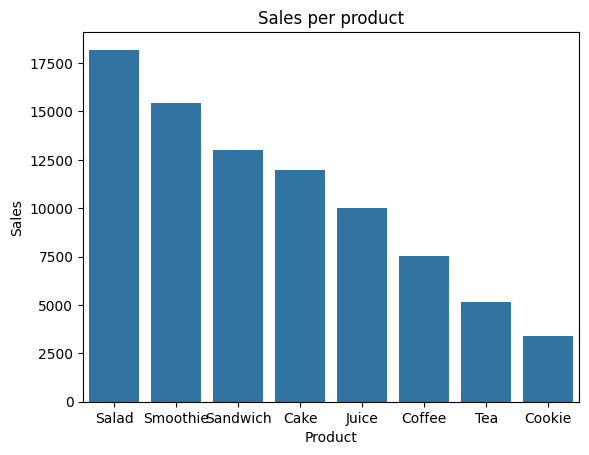

In [ ]:
plt.title("Sales per product")
plt.xlabel("Product")
plt.ylabel("Sales")
sns.barplot(x=sales_category.index, y=sales_category.values)
plt.show()

En la grafica anterior se puede visualizar la el producto con mayor volumen de ventas teniendo en cuenta el monto total. no se puede determinar el producto con mayores ventas porque omitimos el precio unitario y cantidades. se realiza este analsis posteriormente en SQL. En esta caso salad tiene el mayor volumen monetario con 18190, seguido de Smoothie con 15412

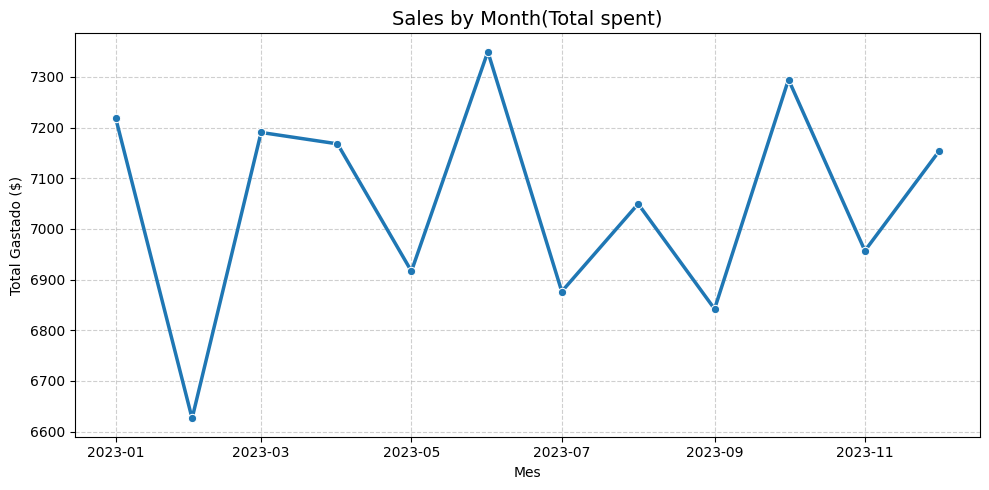

In [ ]:
# Agrupamos los datos por mes y sumamos las ventas
month_sales = sales_coffe.groupby(sales_coffe['Transaction Date'].dt.to_period('M'))['Total Spent'].sum().reset_index()
month_sales['Transaction Date'] = month_sales['Transaction Date'].dt.to_timestamp()

# Creamos el gráfico de línea
plt.figure(figsize=(10, 5))
sns.lineplot(x='Transaction Date', y='Total Spent', data=month_sales, marker='o', linewidth=2.5)

plt.title('Sales by Month(Total spent)', fontsize=14)
plt.xlabel('Mes')
plt.ylabel('Total Gastado ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

En la grafica anterior podemos visualizar las ventas totatales poca cada mes. podemos notar que los meses con mayor volumen de ventas es junio y octubre. lo cual nos podria llevar a un posible hipotesis de si es un negocio estacional.

In [ ]:
sales_category = sales_coffe.groupby('Location')['Total Spent'].sum().sort_values(ascending=False)
sales_category

,Total Spent
Location,
Unknown,33571.0
In-store,25784.5
Takeaway,25287.5


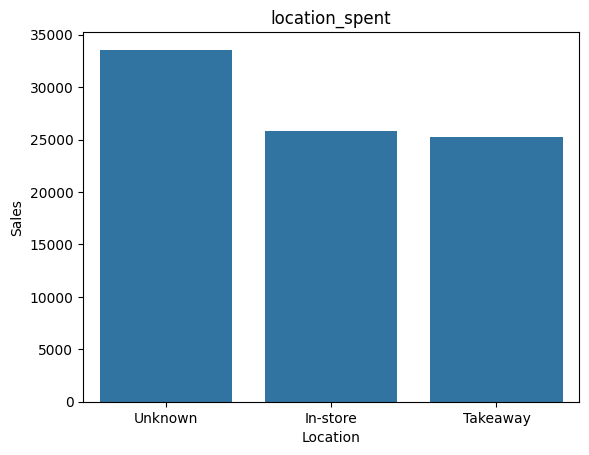

In [ ]:
plt.title("location_spent")
plt.xlabel("Location")
plt.ylabel("Sales")
sns.barplot(x=sales_category.index, y=sales_category.values)
plt.show()

La categoria desconocido nos referencia la falta de un buen seguimiento en la gestion de clientes. esto al momento de poder indetificar necesidades, calidad de servicio e incluso proyecciones para mejoras en los procesos internos

In [ ]:
sales_coffe.to_csv('sales_coffe_clean.csv', index=False)

In [ ]:
from google.colab import files

files.download('sales_coffe_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>